# Tutorial: simulate, map, and fit the beam

This notebook walks through `eigsep_mapmaking` end to end:

1. set up an observation (site, times, pointings, frequencies, band limit);
2. load the beam and the sky (EIGSEP bowtie + GSM2016 from `data/`, or synthetic ones);
3. simulate noisy drift-scan data;
4. make Wiener-filtered maps and look at what the data can constrain;
5. build a beam-error basis, inject an error, and fit it (MAP, Fisher, NUTS);
6. remake the map with the fitted beam.

Each section ends with the knobs worth tuning. The mathematics behind every step is in
[`docs/math.md`](../docs/math.md); section numbers like "math §3" refer to it.

**Data.** With `data/beam.npz` (`python scripts/fetch_beam.py`) and `data/gsm_64.npz`
(`python scripts/make_gsm.py --beam data/beam.npz --fmin 52 --fmax 59 --nside 64`) the notebook
uses the real beam and sky; otherwise it falls back to synthetic ones and runs without any files.

In [1]:
import time
from pathlib import Path

import healpy as hp
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import eigsep_mapmaking  # enables 64-bit JAX
from eigsep_mapmaking import (alm, diagnostics, fitting, instrument, mapmaking,
                              perturbations as pt, simulate, sky)
from eigsep_mapmaking.forward import ForwardModel

REPO = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
DATA = REPO / "data"
USE_DATA = (DATA / "beam.npz").exists() and (DATA / "gsm_64.npz").exists()
print("using", "data/ files" if USE_DATA else "synthetic beam and sky")

using data/ files


## 1. The observation

`Observation` holds everything except the beam pattern and the sky. `Observation.default` is the
notebooks' setup (the site at lat 39.2477, lon −113.4033, a start of 2025-12-01 09:00 UTC, one
sidereal day, tilts 0–90° towards North). Every field can be set by hand, as below.

**Knobs**
- `lmax`: the band limit. Cost grows roughly as lmax³ for the beam set-up and lmax² for the
  fits. 32 runs in a couple of minutes; the beam file supports up to 128.
- `n_times`: needs more than `2 lmax` samples over **exactly one sidereal day** for the exact
  per-m (m-space) solvers (math §3). More samples lower the noise but add no sky modes.
- `pointings`: ZYZ Euler angles from `instrument.pointing_euler(tilt, az, rot)`. Tilt the
  boresight by `tilt` towards compass azimuth `az`, after turning the antenna by `rot` about the
  zenith.
- `integrate=True`: each sample integrates over its slot (a sinc taper per m) instead of being a
  snapshot.
- `Tgnd`, `horizon_theta`: the ground temperature and the horizon (scalar, or a function of
  compass azimuth for terrain).

In [2]:
LMAX = 32
FREQS = np.array([55.0, 56.0])            # MHz; must exist in the beam file
N_POINTINGS = 20
N_TIMES = 2 * LMAX + 8

tilts = np.linspace(0, 90, N_POINTINGS)
pointings = np.stack([instrument.pointing_euler(t, az_deg=0.0) for t in tilts])
times, ends = instrument.uniform_times(N_TIMES, start="2025-12-01 09:00:00", integrate=False)

obs = instrument.Observation(times_jd=times, times_end_jd=ends, freqs=FREQS, lmax=LMAX,
                             pointings=pointings, Tgnd=300.0)
print(f"{obs.n_freqs} freqs, {obs.n_pointings} pointings, {obs.n_times} times, lmax {obs.lmax}")
print("uniform full sidereal day (m-space solvers allowed):", obs.is_uniform_full_day())

2 freqs, 20 pointings, 72 times, lmax 32
uniform full sidereal day (m-space solvers allowed): True


## 2. Beam and sky

The beam is a full-sphere power pattern in the antenna frame (z up, φ = 0 East). The bowtie file
stores it on an MWSS grid at lmax 128, 51–250 MHz. The sky is GSM2016 in galactic HEALPix.
Keep the **whole band** of the beam (`band`): the SVD beam-error basis in §5 is built from it.

In [3]:
if USE_DATA:
    band, band_freqs, BEAM_SAMPLING = instrument.load_beam(DATA / "beam.npz")
    sky_maps, sky_freqs, _ = sky.load_sky(DATA / "gsm_64.npz")
    sky_maps = sky_maps[[int(np.argmin(np.abs(sky_freqs - f))) for f in FREQS]]
else:
    band_freqs = np.arange(50.0, 70.0)
    BEAM_SAMPLING = "healpix"
    band = simulate.synthetic_beam_maps(16, band_freqs)
    sky_maps = simulate.synthetic_sky_maps(16, FREQS, lmax=LMAX)

sel = [int(np.argmin(np.abs(band_freqs - f))) for f in FREQS]
beam = band[sel]
print("beam", beam.shape, BEAM_SAMPLING, "| sky", sky_maps.shape)

beam (2, 130, 258) mwss | sky (2, 49152)


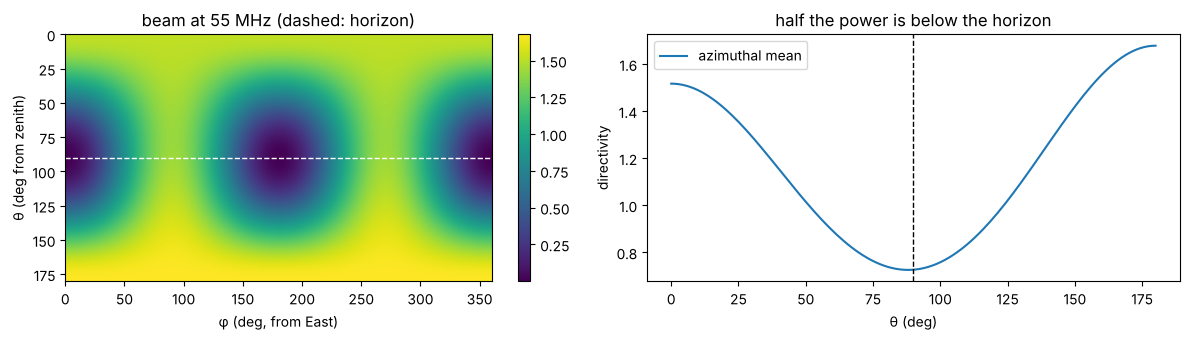

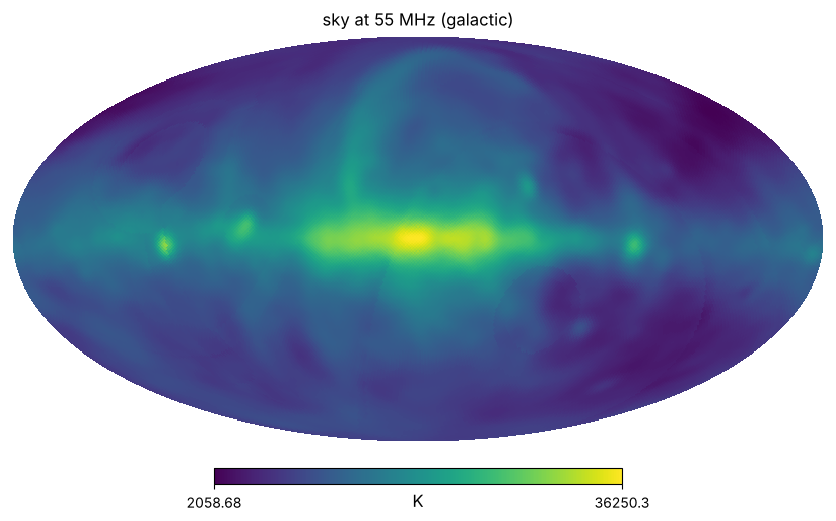

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
if BEAM_SAMPLING == "mwss":
    im = ax[0].imshow(beam[0], aspect="auto", extent=[0, 360, 180, 0])
    ax[0].axhline(90, color="w", ls="--", lw=1)
    ax[0].set(xlabel="φ (deg, from East)", ylabel="θ (deg from zenith)",
              title=f"beam at {FREQS[0]:.0f} MHz (dashed: horizon)")
    plt.colorbar(im, ax=ax[0])
    th = np.linspace(0, 180, beam.shape[1])
    ax[1].plot(th, beam[0].mean(1), label="azimuthal mean")
    ax[1].axvline(90, color="k", ls="--", lw=1)
    ax[1].set(xlabel="θ (deg)", ylabel="directivity", title="half the power is below the horizon")
    ax[1].legend()
else:
    plt.sca(ax[0]); hp.mollview(beam[0], hold=True, title="synthetic beam")
    ax[1].axis("off")
plt.tight_layout()
hp.mollview(sky_maps[0], norm="log", title=f"sky at {FREQS[0]:.0f} MHz (galactic)", unit="K")

## 3. Simulate data

`instrument.beam_response` rotates the beam to each pointing, applies the ground-fixed horizon
and transforms it to croissant's simulation frame. It is linear in the beam pattern.
`simulate.simulate` adds the ground term f_gnd·T_gnd and radiometer noise
σ = T_ant/√(Δν τ), with Δν the channel width and τ the sample length.

**Knobs**
- `noise_scale`: multiplies σ. Raise it to mimic less integration, or to make the beam fit
  harder.
- `stationary=False`: σ(t) ∝ T_ant(t). The m-space solvers then do not apply; use `wiener_cg`.
- `floor`: a fractional model-error term (off by default).

47.1s; y (2, 72, 20) = (freq, time, pointing)
ground fraction per pointing (first freq): [0.516 0.516 0.516 0.516 0.516 0.515 0.514 0.514 0.513 0.512 0.511 0.51
 0.509 0.508 0.506 0.505 0.504 0.503 0.501 0.5  ]
noise sigma (K), first freq: [0.0748 0.0748 0.0749 0.0749 0.075  0.0751 0.0752 0.0753 0.0754 0.0756
 0.0757 0.0759 0.076  0.0762 0.0764 0.0766 0.0768 0.077  0.0772 0.0774]


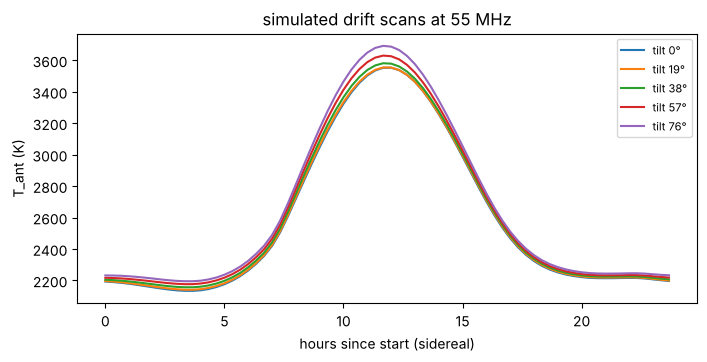

In [5]:
t0 = time.time()
response = instrument.beam_response(beam, obs, sampling=BEAM_SAMPLING)
data = simulate.simulate(beam, sky_maps, obs, beam_sampling=BEAM_SAMPLING, noise_scale=1.0,
                         seed=0, response=response)
print(f"{time.time() - t0:.1f}s; y {data.y.shape} = (freq, time, pointing)")
print("ground fraction per pointing (first freq):", np.round(np.asarray(response.fgnd[:, 0]), 3))
print("noise sigma (K), first freq:", np.round(np.asarray(data.sigma[0, 0]), 4))

lst_h = obs.rotation_angle / (2 * np.pi) * 24
plt.figure(figsize=(8, 3.5))
for p in range(0, N_POINTINGS, 4):
    plt.plot(lst_h, data.y[0, :, p], label=f"tilt {tilts[p]:.0f}°")
plt.xlabel("hours since start (sidereal)"); plt.ylabel("T_ant (K)"); plt.legend(fontsize=8)
plt.title(f"simulated drift scans at {FREQS[0]:.0f} MHz");

## 4. Mapmaking

**What the data can see (math §3.3).** Over a full day each m decouples. Each m-block sees at
most `min(P, lmax + 1 − |m|)` sky modes, so the rank is bounded whatever the number of time
samples. Everything outside that span comes from the prior.

In [6]:
for P in (1, 5, 10, 20, 40):
    b = diagnostics.rank_bound(P, LMAX)
    print(f"{P:3d} pointings: at most {b:5d} of {alm.n_real(LMAX)} sky modes ({b / alm.n_real(LMAX):.0%})")
fm = data.fm
print("numerical rank of this set-up per freq:", diagnostics.mspace_rank(fm, rtol=1e-8))

  1 pointings: at most    65 of 1089 sky modes (6%)
  5 pointings: at most   305 of 1089 sky modes (28%)
 10 pointings: at most   560 of 1089 sky modes (51%)
 20 pointings: at most   920 of 1089 sky modes (84%)
 40 pointings: at most  1089 of 1089 sky modes (100%)


numerical rank of this set-up per freq: [827 826]


**Prior and solvers.** The sky prior is Gaussian and isotropic with power spectrum C_ℓ
(`SkyPrior`):
- `SkyPrior.oracle(true_alm, floor)` takes C_ℓ from the true sky, as the old notebooks did.
  It is optimistic.
- `SkyPrior.power_law(lmax, freqs, amp, alpha, beta, nu0, monopole_sigma)` makes no use of the
  truth.

Two solvers give the same answer:
- `wiener_mspace` is exact and fast for a full uniform day with stationary noise.
- `wiener_cg` is the general one (any sampling, σ(t)).

`posterior_var_mspace` gives the posterior variance of every coefficient.

In [7]:
x_true = data.x_true
prior_oracle = sky.SkyPrior.oracle(alm.unpack(x_true), floor=1e-4)
cl_true = np.asarray(alm.cl_from_packed(x_true))
amp = float(cl_true[0, 2] * 2**2.5)  # a rough power law through l = 2
prior_pl = sky.SkyPrior.power_law(LMAX, FREQS, amp=amp, alpha=2.5, beta=2.5, nu0=FREQS[0],
                                  monopole_sigma=float(np.sqrt(cl_true[0, 0] / (4 * np.pi))))

t0 = time.time()
x_or = mapmaking.wiener_mspace(fm, prior_oracle, data.sigma, data.y)
x_pl = mapmaking.wiener_mspace(fm, prior_pl, data.sigma, data.y)
print(f"m-space Wiener filters: {time.time() - t0:.1f}s")
t0 = time.time()
x_cg, resid = mapmaking.wiener_cg(fm, prior_oracle, data.sigma, data.y, tol=1e-8)
print(f"CG: {time.time() - t0:.1f}s, residual {float(resid):.1e}, "
      f"|CG - m-space| / |m-space| = {diagnostics.relative_error(x_cg, x_or):.1e}")
for name, x in [("oracle prior", x_or), ("power-law prior", x_pl)]:
    print(f"{name}: relative map error {diagnostics.relative_error(x, x_true):.3f}")

m-space Wiener filters: 2.0s


CG: 9.8s, residual 1.1e-08, |CG - m-space| / |m-space| = 2.6e-05
oracle prior: relative map error 0.241
power-law prior: relative map error 0.244


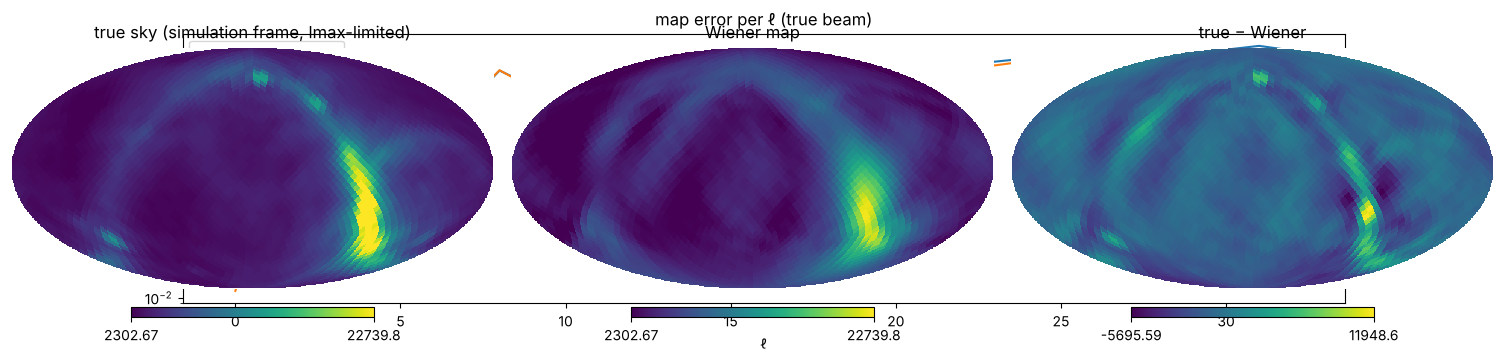

In [8]:
ell = np.arange(LMAX + 1)
plt.figure(figsize=(7, 3.5))
plt.semilogy(ell, diagnostics.map_error_per_ell(x_or, x_true)[0], label="oracle prior")
plt.semilogy(ell, diagnostics.map_error_per_ell(x_pl, x_true)[0], label="power-law prior")
plt.xlabel("ℓ"); plt.ylabel("√(C_ℓ(error) / C_ℓ(true))"); plt.legend()
plt.title("map error per ℓ (true beam)");

NSIDE_PLOT = 16  # needs 2 * NSIDE_PLOT <= LMAX + 1
true_map = sky.sky_maps_from_alm(alm.unpack(x_true[0]), NSIDE_PLOT)
wf_map = sky.sky_maps_from_alm(alm.unpack(x_or[0]), NSIDE_PLOT)
sd_map = np.sqrt(np.asarray(mapmaking.posterior_var_mspace(fm, prior_oracle, data.sigma)[0]))
vmin, vmax = np.percentile(true_map, [1, 99])
hp.mollview(true_map, title="true sky (simulation frame, lmax-limited)", min=vmin, max=vmax, sub=131)
hp.mollview(wf_map, title="Wiener map", min=vmin, max=vmax, sub=132)
hp.mollview(true_map - wf_map, title="true − Wiener", sub=133)
plt.gcf().set_size_inches(15, 3.5)

Constrained realizations are draws from the sky posterior: the Wiener map plus a fluctuation
consistent with the data and the prior. `clip_positive_for_display` exists for plots only: a
clipped map is not a valid estimate, and it must never feed the beam fit.

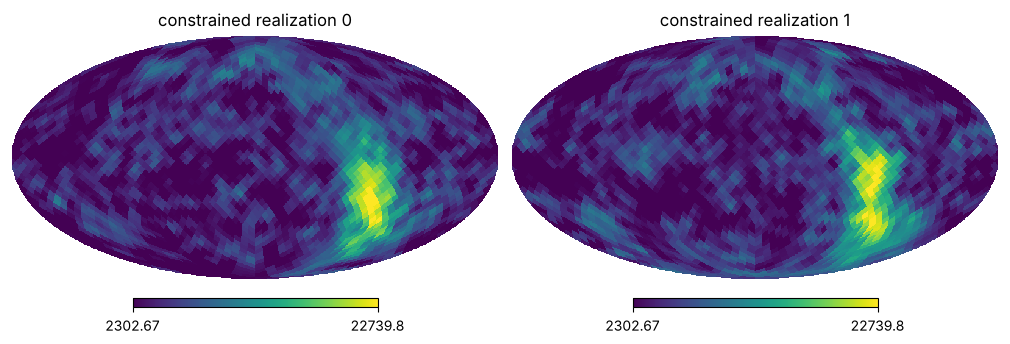

In [9]:
draws = [mapmaking.constrained_realization(fm, prior_oracle, data.sigma, data.y, jax.random.PRNGKey(k))
         for k in range(2)]
for k, x in enumerate(draws):
    hp.mollview(sky.sky_maps_from_alm(alm.unpack(x[0]), NSIDE_PLOT), min=vmin, max=vmax,
                title=f"constrained realization {k}", sub=(1, 2, k + 1))
plt.gcf().set_size_inches(10, 3.5)

## 5. Beam errors

The data are invariant to B → c·B at each frequency, because the visibility is divided by ∫B.
Beam-error modes therefore have that "scale direction" removed (math §5.2). Two bases:
- `svd_basis(band, k, select=...)` is built from the SVD of the beam over the **whole band**
  and evaluated at the fitted channels.
- `lowl_basis(beam, lmax_pert, n_freq_funcs)` uses generic multiplicative modes
  B·Y_ℓm·P_j(ν).

Modes are scaled to the beam RMS, so β_k = 0.05 means a 5% RMS error. That is also the default
prior σ (`rel_sigma`).

**Knobs:** `k` (number of modes), `rel_sigma` (prior width), the basis type.
`diagnostics.mode_overlap` tells you how much of a given beam error a basis can represent.

In [10]:
basis = pt.svd_basis(band, k=3, sampling=BEAM_SAMPLING, select=sel, rel_sigma=0.05)
raw = pt.svd_basis(band, k=1, sampling=BEAM_SAMPLING, select=sel, remove=False)
print("fraction of the raw leading SVD mode along the (invisible) scale direction:",
      np.round(diagnostics.scale_fraction(raw.modes[0], beam, BEAM_SAMPLING), 3))

beta_true = np.array([1.5, -1.0, 0.5]) * basis.sigma   # inject an in-basis error
beam_true = pt.inject_error(beam, basis, beta_true)
print("injected beta:", beta_true)
print("normalized beam error of the nominal beam:",
      np.round(diagnostics.normalized_beam_error(beam, beam_true, BEAM_SAMPLING), 4))

fraction of the raw leading SVD mode along the (invisible) scale direction: [0.902 0.903]
injected beta: [ 0.075 -0.05   0.025]
normalized beam error of the nominal beam: [0.0939 0.0935]


Now simulate the data with the **true** (perturbed) beam, and analyse it with the **nominal**
one. `LinearBeamModel` precomputes the responses of the nominal beam and of each mode once.
`lin.forward_model(beta)` is then cheap and differentiable in β, with no spherical-harmonic
transforms inside the likelihood.

In [11]:
t0 = time.time()
lin = pt.LinearBeamModel.build(beam, basis, obs, sampling=BEAM_SAMPLING)
data_pert = simulate.simulate(beam_true, sky_maps, obs, beam_sampling=BEAM_SAMPLING, seed=1)
print(f"{time.time() - t0:.1f}s")
x_nom = mapmaking.wiener_mspace(lin.forward_model(jnp.zeros(basis.k)), prior_oracle,
                                data_pert.sigma, data_pert.y)
x_tb = mapmaking.wiener_mspace(data_pert.fm, prior_oracle, data_pert.sigma, data_pert.y)
print(f"map error with the nominal beam {diagnostics.relative_error(x_nom, data_pert.x_true):.3f}, "
      f"with the true beam {diagnostics.relative_error(x_tb, data_pert.x_true):.3f}")

2.2s


map error with the nominal beam 5.433, with the true beam 0.182


## 6. Fitting the beam

The likelihood marginalizes the sky analytically, p(y | β) = N(y; g(β), A(β) S A(β)ᵀ + N), and
splits into small Gaussians per (frequency, m) (math §6.2). There is no sky estimate in the loop.

1. `find_map` finds the MAP with BFGS from β = 0 and several prior draws. The posterior can
   have secondary modes, which multiple starts guard against.
2. `fisher` gives the expected errors. `whiten` gives the best- and worst-constrained
   directions.
3. `run_nuts` samples the posterior, starting at the MAP.

**Knobs:** the prior (`prior_oracle` vs `prior_pl`; a wrong prior biases β), `n_starts` in
`find_map`, `num_warmup`/`num_samples` in `run_nuts`.

In [12]:
t0 = time.time()
beta_map, logp = fitting.find_map(lin, prior_oracle, data_pert.sigma, data_pert.y, basis.sigma)
print(f"MAP {np.round(beta_map, 4)} (true {beta_true}), log posterior {logp:.1f}, {time.time() - t0:.1f}s")
F = fitting.fisher(jnp.asarray(beta_map), lin, prior_oracle, data_pert.sigma)
print("Fisher errors:", np.sqrt(np.diag(np.linalg.inv(F))))
w, v = fitting.whiten(F)
print("whitened directions: errors", 1 / np.sqrt(w))

MAP [ 0.0757 -0.0505  0.0232] (true [ 0.075 -0.05   0.025]), log posterior 8176.0, 6.8s


Fisher errors: [0.0003664  0.00030297 0.00068669]
whitened directions: errors [0.0001777  0.00034387 0.0007401 ]


NUTS 45.5s
beta_0: +0.0758 ± 0.0003   (true +0.0750)
beta_1: -0.0504 ± 0.0003   (true -0.0500)
beta_2: +0.0232 ± 0.0009   (true +0.0250)


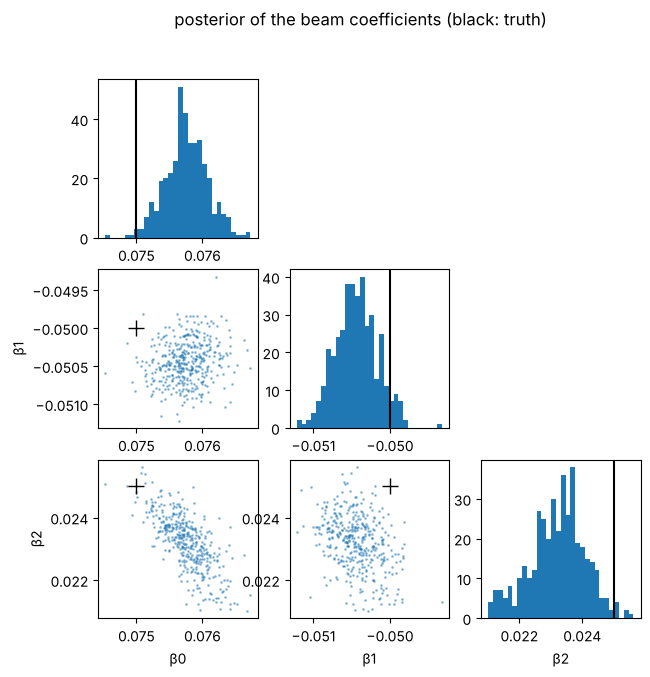

In [13]:
t0 = time.time()
samples = np.asarray(fitting.run_nuts(lin, prior_oracle, data_pert.sigma, data_pert.y,
                                      basis.sigma, num_warmup=200, num_samples=400, key=0))
print(f"NUTS {time.time() - t0:.1f}s")
for k in range(basis.k):
    print(f"beta_{k}: {samples[:, k].mean():+.4f} ± {samples[:, k].std():.4f}   (true {beta_true[k]:+.4f})")

K = basis.k
fig, ax = plt.subplots(K, K, figsize=(7, 7))
for i in range(K):
    for j in range(K):
        a = ax[i, j]
        if j > i:
            a.axis("off"); continue
        if i == j:
            a.hist(samples[:, i], 30, color="C0"); a.axvline(beta_true[i], color="k")
        else:
            a.plot(samples[:, j], samples[:, i], ".", ms=2, alpha=0.4)
            a.plot(beta_true[j], beta_true[i], "k+", ms=12)
        if i == K - 1: a.set_xlabel(f"β{j}")
        if j == 0 and i > 0: a.set_ylabel(f"β{i}")
fig.suptitle("posterior of the beam coefficients (black: truth)");

## 7. Results with the fitted beam

Compare the beams after normalizing each (B/∫B); only the normalized beam is observable. Then
remake the map with the fitted beam.

normalized beam error: nominal [0.0939 0.0935] -> fitted [0.0021 0.0021]
map error with nominal beam : 5.433
map error with fitted beam  : 0.195
map error with true beam    : 0.182


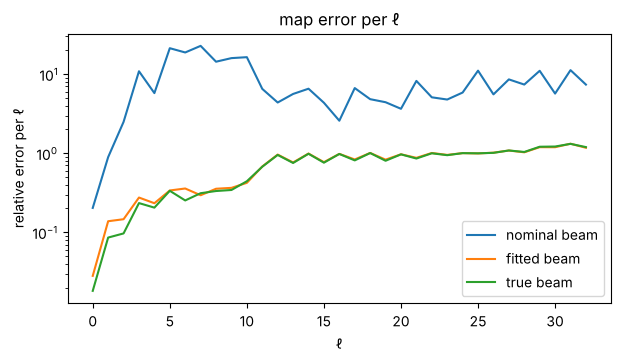

In [14]:
beta_fit = samples.mean(0)
beam_fit = pt.inject_error(beam, basis, beta_fit)
x_fit = mapmaking.wiener_mspace(lin.forward_model(jnp.asarray(beta_fit)), prior_oracle,
                                data_pert.sigma, data_pert.y)
print("normalized beam error: nominal", np.round(diagnostics.normalized_beam_error(beam, beam_true, BEAM_SAMPLING), 4),
      "-> fitted", np.round(diagnostics.normalized_beam_error(beam_fit, beam_true, BEAM_SAMPLING), 4))
for name, x in [("nominal beam", x_nom), ("fitted beam", x_fit), ("true beam", x_tb)]:
    print(f"map error with {name:13s}: {diagnostics.relative_error(x, data_pert.x_true):.3f}")

plt.figure(figsize=(7, 3.5))
for name, x in [("nominal beam", x_nom), ("fitted beam", x_fit), ("true beam", x_tb)]:
    plt.semilogy(ell, diagnostics.map_error_per_ell(x, data_pert.x_true)[0], label=name)
plt.xlabel("ℓ"); plt.ylabel("relative error per ℓ"); plt.legend(); plt.title("map error per ℓ");

## 8. Where to go from here

| want to… | change |
|---|---|
| higher resolution | `LMAX` (and `N_TIMES > 2 LMAX`); the beam file supports up to 128 |
| other frequencies | `FREQS` (channels of the beam file; regenerate the GSM file for them) |
| more or different pointings | `pointing_euler(tilt, az, rot)` per pointing |
| integrating samples | `uniform_times(..., integrate=True)` |
| noisier data | `noise_scale` in `simulate` |
| a non-oracle prior | `SkyPrior.power_law(...)` in both the Wiener filter and the fit |
| a different beam-error model | `svd_basis(k=...)`, `lowl_basis(lmax_pert, n_freq_funcs)`, `rel_sigma` |
| an error outside the basis | inject `beam_true = beam + any_delta`, check `diagnostics.mode_overlap(basis, any_delta)` |
| partial days / σ(t) | use `wiener_cg`; the m-space likelihood does not apply (a time-domain sampler is a follow-up) |
| a terrain horizon | `Observation(horizon_theta=lambda A: ...)` (compass azimuth in radians) |

For a scripted version of §§3–7, see `examples/simulate_map_and_fit.py`.